# LRB-D with two ancillas on the conventional sites: SI1000 and SD6, qutrit and qubit

This notebook plots the four production LRB-D runs of the conventional-site two-ancilla layout (`folded_qutrit_conv_sites`, `folded_qubit_conv_sites`), the counterpart of `notebooks/04-qutrit-one-and-relay-two-ancilla-si1000-sd6.ipynb` and `notebooks/05-qubit-one-and-relay-two-ancilla-si1000-sd6.ipynb`.

**Layout.** The data sit as in the paper's patch, $q_2$ at the centre, and the ancillas at the four conventional sites between them: N touches $q_0,q_1,q_2$; W touches $q_0,q_2,q_3$; E touches $q_1,q_2,q_4$; S touches $q_2,q_3,q_4$. Every two-qudit gate couples a site to one of its own data qudits; no two sites are coupled.

- $G_3$ is measured on N and $G_2$ on E.
- $G_1$ and $G_4$ contain the opposite corners $q_1$ and $q_3$, so no site covers them. They use a data relay: N collects $-z_1$ and lends it to $q_0$, W reads $q_0$ and $q_3$, then N takes it back. For $G_4$, E lends its $q_1$ part to $q_4$ in the X basis and S reads $q_4$ and $q_3$.
- N measures $G_3$ before lending and E lends before measuring $G_2$, so every site is read once per round (4 readouts, one reset moment and one measurement moment per round, 11 gate moments).
- The readouts are $G_3$, $G_1+G_3$, $G_2$, $G_4$; all four must vanish.

| | SI1000 | SD6 |
|---|---|---|
| qutrit `[[5,1,2]]_3` (`folded_qutrit_conv_sites`) | ✓ | ✓ |
| qubit `[[5,1,2]]` (`folded_qubit_conv_sites`) | ✓ | ✓ |

Everything else (Clifford groups, SI1000/SD6 noise on an ASAP moment schedule with idle noise, ancilla reset right before each check round, mirror inverse, grids, fits) is the same as in the existing notebooks. Section 8 compares these runs with the existing one-ancilla and coherent-relay two-ancilla runs, read from their saved tables without rebuilding them.


### 0. Environment check

The kernel should be the repo venv (`.venv-sdim140`), which pins sdim 1.4.0.

In [1]:
from importlib.metadata import version
version("sdim")

'1.4.0'

### 1. Shared imports and configuration

Same fit, threshold, GIF and paper settings as the earlier DEM notebooks, except the axis is the two-qudit gate error $p$ (`p_axis_scale=1.0`).

In [2]:
from pathlib import Path
import sys
import importlib

import pandas as pd
from IPython.display import Image, display


def find_repo_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "src" / "lrb" / "lrb_plotting.py").exists():
            return candidate
    raise FileNotFoundError("Could not locate repository root containing src/lrb/lrb_plotting.py")


REPO_ROOT = find_repo_root(Path.cwd())
SRC_PATH = REPO_ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

import lrb.lrb_plotting as _lrb_plotting
import lrb.lrb_gif_plotting as _lrb_gif_plotting

# Ensure notebook uses latest local edits to plotting/GIF modules.
importlib.reload(_lrb_plotting)
importlib.reload(_lrb_gif_plotting)

from lrb.lrb_plotting import (
    LRBPlotFitConfig,
    LRBResultsPlotter,
    LRBThresholdConfig,
    LRBPaperPlotConfig,
)
from lrb.lrb_gif_plotting import LRBGifAnimator, LRBGifRenderConfig


def resolve_working_folder(
    code_name: str,
    lrb_root=None,
) -> str:
    root = Path(lrb_root) if lrb_root is not None else REPO_ROOT / "LRB-experiment-data-slurm"
    code_marker = root / f"working-folder-{code_name}.txt"
    legacy_marker = root / "working-folder.txt"

    def marker_path(marker: Path):
        if not marker.exists():
            return None
        run_name = marker.read_text(encoding="utf-8").strip()
        if not run_name:
            return None
        run_path = root / run_name
        if not run_path.exists():
            return None
        return str(run_path) + "/"

    for marker in (code_marker, legacy_marker):
        maybe_path = marker_path(marker)
        if maybe_path is not None:
            return maybe_path

    candidates = sorted(
        root.glob(f"Run-*-{code_name}*"),
        key=lambda p: p.stat().st_mtime,
        reverse=True,
    )
    if candidates:
        return str(candidates[0]) + "/"

    raise FileNotFoundError(
        f"No run folder found for code '{code_name}' under {root.resolve()}"
    )


fit_config = LRBPlotFitConfig(
    a_fixed=0.0,
    y_ceiling=1.0,
    min_fit_points_lrb=2,
    min_fit_points_rb=3,
    f_min=1e-8,
    f_max=1.0000000,
    rb_a_fixed=0.0,
    # SI1000 and SD6 are parameterized by the two-qudit gate depolarizing
    # probability p (Gidney et al. 2021); plot against it directly.
    p_axis_scale=1.0,
    p_axis_label="Two-qudit gate error rate $p$",
    p_axis_symbol="p",
    p_axis_column=None,
)

threshold_config = LRBThresholdConfig(
    tol=5e-4,
    require_consecutive=2,
    ignore_first_n=3,
    err_floor=2e-3,
    tail_min_prefix=6,
    tail_drop_tol_abs=0.01,
    tail_drop_tol_rel=0.25,
    p_min=None,
    p_max=None,
    min_lrb_n_points_keep=0,
    min_rb_n_points_keep=0,
    zoom_half_window_points=4,
    zoom_pad_frac=0.25,
    min_zoom_span=0.01,
    p_window_before_points=8,
    p_window_after_points=5,
    min_points_in_view=6,
    view_pad_frac=0.15,
    bootstrap_reps_error=500,
    bootstrap_reps_threshold=1000,
    bootstrap_ci_level=0.68,
    bootstrap_use_sem=True,
    bootstrap_seed=12345,
    paper_mode=True,
    paper_cols=2,
    paper_panel_width_in=3.2,
    paper_panel_height_in=2.5,
)

# Shared check ranges for all multi-check plotting/table methods.
const_check_min = 0
const_check_max = 0
unif_check_min = 1
unif_check_max = 22

# Optional pseudo-threshold fit controls.
pseudo_do_fit = False
pseudo_fit_model = "exp"  # or "poly"
pseudo_fit_degree = 1


gif_render_config = LRBGifRenderConfig(
    fps=10,
    dpi=120,
    hold_frames=1,
    transition_frames=6,
)

paper_plot_config = LRBPaperPlotConfig(
    enabled=True,
    column_layout="double",
    rows_per_page=3,
    pairs_per_row=2,
    num_prob_samples=6,
    # Circuit-level range on the production grid:
    # p = 1e-4, 5e-4, 1e-3, 2e-3, 5e-3, 1e-2.
    prob_sample_indices=(1, 3, 4, 5, 6, 8),
    row_height_in=1.6,
    panel_title_fontsize=7.0,
    axis_label_fontsize=6.6,
    tick_fontsize=6.0,
    legend_fontsize=5.7,
    line_width=0.85,
    marker_size=2.6,
    errorbar_capsize=1.2,
    show_legend_first_row_only=False,
    compact_fit_legend=True,
    legend_on_rejected_panel=True,
)

def show_error_rate_uncertainty_table(table_csv: str, label: str) -> pd.DataFrame:
    frame = pd.read_csv(table_csv)
    coordinate_columns = [
        c for c in ("lrb_lambda", "rb_p", "lambda", "p_raw", "p")
        if c in frame.columns
    ]
    sort_column = "lrb_lambda" if "lrb_lambda" in frame.columns else coordinate_columns[0]
    needed = [
        "check_num",
        *coordinate_columns,
        "lrb_error_rate",
        "lrb_error_rate_ci_low",
        "lrb_error_rate_ci_high",
        "rb_error_rate",
        "rb_error_rate_ci_low",
        "rb_error_rate_ci_high",
    ]
    missing = [c for c in needed if c not in frame.columns]
    if missing:
        raise ValueError(
            f"Missing uncertainty columns in {table_csv}: {missing}. "
            "Re-run the table generation cell."
        )

    view = frame[needed].copy()
    view["lrb_unc_minus"] = view["lrb_error_rate"] - view["lrb_error_rate_ci_low"]
    view["lrb_unc_plus"] = view["lrb_error_rate_ci_high"] - view["lrb_error_rate"]
    view["rb_unc_minus"] = view["rb_error_rate"] - view["rb_error_rate_ci_low"]
    view["rb_unc_plus"] = view["rb_error_rate_ci_high"] - view["rb_error_rate"]
    view = view.sort_values(["check_num", sort_column]).reset_index(drop=True)

    print(f"[{label}] error-rate uncertainty table")
    display(view)
    return view

def show_pseudo_threshold_uncertainty_table(
    summary_csv: str,
    label: str,
    check_min=None,
    check_max=None,
) -> pd.DataFrame:
    frame = pd.read_csv(summary_csv)
    threshold_column = (
        "threshold_lrb_lambda"
        if "threshold_lrb_lambda" in frame.columns
        else "threshold_lambda"
        if "threshold_lambda" in frame.columns
        else "threshold_p"
    )
    threshold_std_column = f"{threshold_column}_std_boot"
    threshold_ci_low_column = f"{threshold_column}_ci_low"
    threshold_ci_high_column = f"{threshold_column}_ci_high"
    needed = ["check_num", threshold_column]
    missing = [c for c in needed if c not in frame.columns]
    if missing:
        raise ValueError(
            f"Missing pseudo-threshold columns in {summary_csv}: {missing}. "
            "Re-run threshold generation first."
        )

    view = frame.copy()
    if check_min is not None:
        view = view[view["check_num"] >= int(check_min)]
    if check_max is not None:
        view = view[view["check_num"] <= int(check_max)]
    view = view[view[threshold_column].notna()].copy()

    keep = ["check_num", threshold_column]
    has_std = threshold_std_column in view.columns
    has_ci = (
        threshold_ci_low_column in view.columns
        and threshold_ci_high_column in view.columns
    )
    if has_std:
        keep.append(threshold_std_column)
    if has_ci:
        keep.extend([threshold_ci_low_column, threshold_ci_high_column])

    table = view[keep].copy()
    if has_ci:
        table["threshold_unc_minus"] = (
            table[threshold_column] - table[threshold_ci_low_column]
        )
        table["threshold_unc_plus"] = (
            table[threshold_ci_high_column] - table[threshold_column]
        )
    elif has_std:
        table["threshold_unc_minus"] = table[threshold_std_column]
        table["threshold_unc_plus"] = table[threshold_std_column]
    else:
        raise ValueError(
            f"No pseudo-threshold uncertainty columns found in {summary_csv}."
        )

    table = table.sort_values(["check_num"]).reset_index(drop=True)
    print(f"[{label}] pseudo-threshold uncertainty table")
    display(table)
    return table

### 2. Run selection and output audit

Runs are named explicitly so the notebook does not depend on the mutable `working-folder-*.txt` pointers. The audit requires every LRB and RB CSV before plotting.

In [3]:
RUNS_ROOT = REPO_ROOT / "LRB-experiment-data-slurm"
RUN_NAMES = {
    "conv_qutrit_si1000": "Run-2026-11-01-09-22-32-folded_qutrit_conv_sites-conv-sites-si1000-sdim140",
    "conv_qutrit_sd6": "Run-2026-11-01-09-24-10-folded_qutrit_conv_sites-conv-sites-sd6-sdim140",
    "conv_qubit_si1000": "Run-2026-11-01-09-26-44-folded_qubit_conv_sites-conv-sites-si1000-sdim140",
    "conv_qubit_sd6": "Run-2026-11-01-09-28-00-folded_qubit_conv_sites-conv-sites-sd6-sdim140",
}
EXPECTED_METADATA = {
    "conv_qutrit_si1000": ("folded_qutrit_conv_sites", "si1000"),
    "conv_qutrit_sd6": ("folded_qutrit_conv_sites", "sd6"),
    "conv_qubit_si1000": ("folded_qubit_conv_sites", "si1000"),
    "conv_qubit_sd6": ("folded_qubit_conv_sites", "sd6"),
}


def read_int_list(path: Path) -> list[int]:
    return [int(v) for v in path.read_text().replace(",", " ").split()]


def read_float_list(path: Path) -> list[float]:
    return [float(v) for v in path.read_text().replace(",", " ").split()]


def audit_run(label: str, run_path: Path) -> pd.DataFrame:
    code_name = (run_path / "code_name.txt").read_text().strip()
    noise_model = (run_path / "noise_model.txt").read_text().strip()
    if (code_name, noise_model) != EXPECTED_METADATA[label]:
        raise ValueError(f"{label}: found {(code_name, noise_model)}, expected {EXPECTED_METADATA[label]}")
    probs = read_float_list(run_path / "probs.txt")
    const_checks = read_int_list(run_path / "check_const.txt")
    unif_checks = read_int_list(run_path / "check_unif.txt")
    rows = []
    for idx, prob in enumerate(probs):
        lrb_path = run_path / "results" / "LRB" / str(idx)
        done_path = run_path / "progress" / str(idx) / "done.txt"
        rows.append({
            "run": label,
            "p_index": idx,
            "p": prob,
            "done_flag": done_path.read_text().strip() if done_path.exists() else "missing",
            "const_csvs": len(list((lrb_path / "const_check_data").glob("*.csv"))),
            "expected_const_csvs": len(const_checks),
            "unif_csvs": len(list((lrb_path / "unif_check_data").glob("*.csv"))),
            "expected_unif_csvs": len(unif_checks),
            "rb_csv_present": (run_path / "results" / "RB" / f"{idx}.csv").exists(),
        })
    return pd.DataFrame(rows)


run_paths = {label: RUNS_ROOT / name for label, name in RUN_NAMES.items()}
audit = pd.concat([audit_run(label, path) for label, path in run_paths.items()], ignore_index=True)
summary = audit.groupby("run").agg(
    indices=("p_index", "count"),
    done=("done_flag", lambda s: int((s == "1").sum())),
    lrb_csvs=("const_csvs", "sum"),
    unif_csvs=("unif_csvs", "sum"),
    expected_const=("expected_const_csvs", "sum"),
    expected_unif=("expected_unif_csvs", "sum"),
    rb_csvs=("rb_csv_present", "sum"),
)
display(summary)
incomplete = audit[
    (audit["done_flag"] != "1")
    | (audit["const_csvs"] != audit["expected_const_csvs"])
    | (audit["unif_csvs"] != audit["expected_unif_csvs"])
    | (~audit["rb_csv_present"])
]
if not incomplete.empty:
    raise ValueError("Incomplete runs/indices:\n" + incomplete.to_string())

,indices,done,lrb_csvs,unif_csvs,expected_const,expected_unif,rb_csvs
run,,,,,,,
conv_qubit_sd6,15,15,345,330,345,330,15
conv_qubit_si1000,15,15,345,330,345,330,15
conv_qutrit_sd6,15,15,345,330,345,330,15
conv_qutrit_si1000,15,15,345,330,345,330,15


### 3. Build plotters

One `LRBResultsPlotter` per run. With `p_axis_scale=1.0` and no `rb_comparison_probs.txt`, each plotter pairs LRB at $p$ with physical RB at the same $p$ from `results/RB`.

In [4]:
plotters = {
    label: LRBResultsPlotter(working_folder=str(path) + "/", fit_config=fit_config)
    for label, path in run_paths.items()
}
for label, plotter in plotters.items():
    rb_source, rb_probabilities = plotter._rb_table_source()
    print(f"{label}: {plotter.code_title}")
    print(f"  p grid: {plotter.probabilities}")
    print(f"  RB source: {rb_source}")
    if max(abs(a - b) for a, b in zip(plotter.probabilities, rb_probabilities)) > 0:
        raise ValueError(f"{label}: RB grid is not the LRB p grid.")

conv_qutrit_si1000: $[[5,1,2]]_3$ two-ancilla sites, SI1000
  p grid: [0.0, 0.0001, 0.0002, 0.0005, 0.001, 0.002, 0.005, 0.0075, 0.01, 0.0125, 0.015, 0.02, 0.03, 0.04, 0.05]
  RB source: /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-22-32-folded_qutrit_conv_sites-conv-sites-si1000-sdim140/results/RB
conv_qutrit_sd6: $[[5,1,2]]_3$ two-ancilla sites, SD6
  p grid: [0.0, 0.0001, 0.0002, 0.0005, 0.001, 0.002, 0.005, 0.0075, 0.01, 0.0125, 0.015, 0.02, 0.03, 0.04, 0.05]
  RB source: /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-24-10-folded_qutrit_conv_sites-conv-sites-sd6-sdim140/results/RB
conv_qubit_si1000: $[[5,1,2]]_2$ two-ancilla sites, SI1000
  p grid: [0.0, 0.0001, 0.0002, 0.0005, 0.001, 0.002, 0.005, 0.0075, 0.01, 0.0125, 0.015, 0.02, 0.03, 0.04, 0.05]
  RB source: /pscratch/sd/s/sohan100/worktrees/LRB-Simul

### 4. Constant-check plots

`const_check=0` (the direct terminal-X check) for every run, as in the earlier notebooks.

=== conv_qutrit_si1000


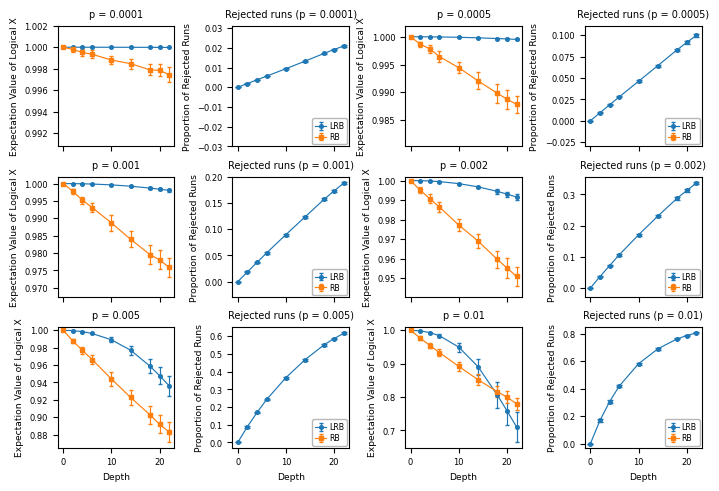

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-22-32-folded_qutrit_conv_sites-conv-sites-si1000-sdim140/results/plots/const-0-Summary-Graph-NoFit.pdf
=== conv_qutrit_sd6


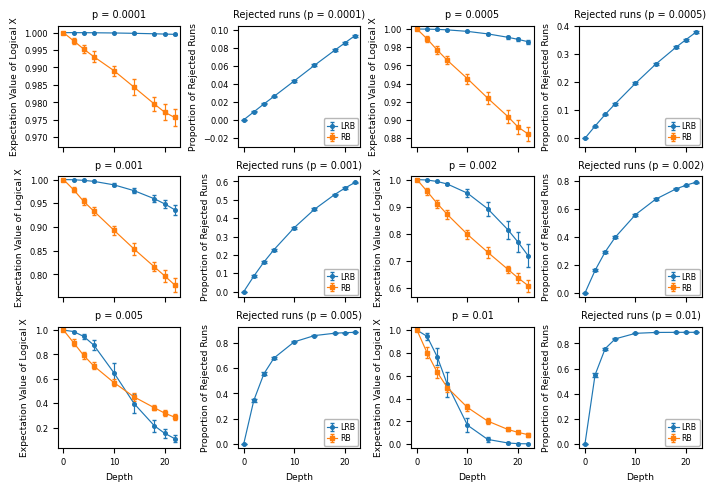

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-24-10-folded_qutrit_conv_sites-conv-sites-sd6-sdim140/results/plots/const-0-Summary-Graph-NoFit.pdf
=== conv_qubit_si1000


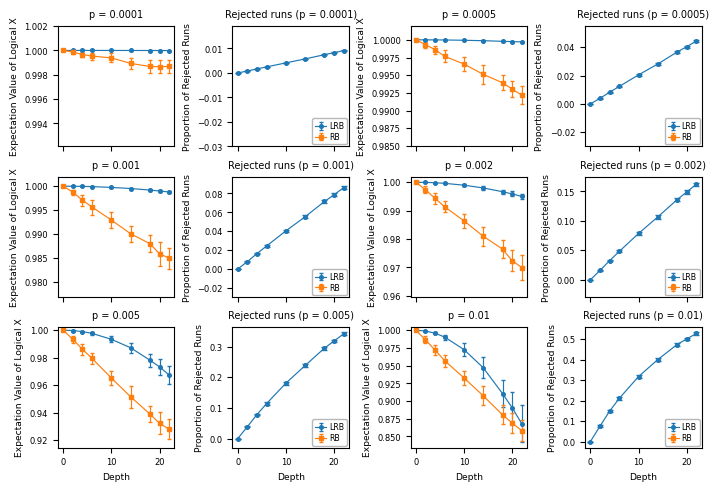

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-26-44-folded_qubit_conv_sites-conv-sites-si1000-sdim140/results/plots/const-0-Summary-Graph-NoFit.pdf
=== conv_qubit_sd6


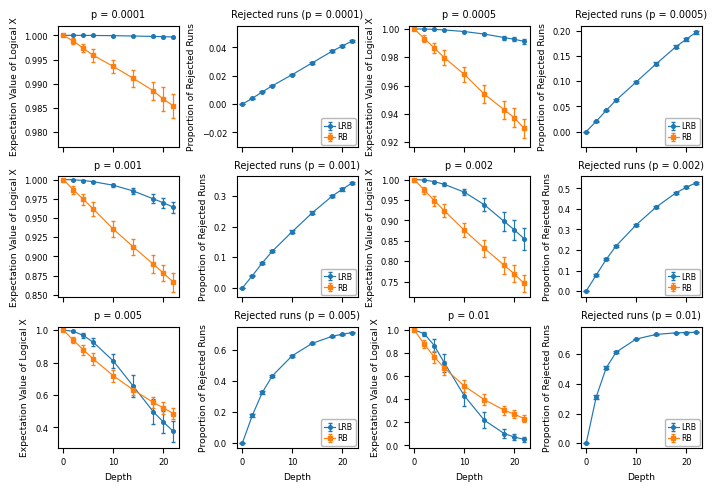

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-28-00-folded_qubit_conv_sites-conv-sites-sd6-sdim140/results/plots/const-0-Summary-Graph-NoFit.pdf


{'conv_qutrit_si1000': ['/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-22-32-folded_qutrit_conv_sites-conv-sites-si1000-sdim140/results/plots/const-0-Summary-Graph-NoFit.pdf'],
 'conv_qutrit_sd6': ['/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-24-10-folded_qutrit_conv_sites-conv-sites-sd6-sdim140/results/plots/const-0-Summary-Graph-NoFit.pdf'],
 'conv_qubit_si1000': ['/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-26-44-folded_qubit_conv_sites-conv-sites-si1000-sdim140/results/plots/const-0-Summary-Graph-NoFit.pdf'],
 'conv_qubit_sd6': ['/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-28-00-folded_qubit_conv_sites-conv-sites-sd6-sdim140/r

In [5]:
const_outputs = {}
for label, plotter in plotters.items():
    print(f"=== {label}")
    const_outputs[label] = plotter.plot_all_const_checks(
        show=True,
        check_min=0,
        check_max=0,
        paper_config=paper_plot_config,
    )
const_outputs

### 5. Uniform-check plots

Interval checks `1..4` for every run; raise `unif_plot_max` to `unif_check_max` for all intervals.

=== conv_qutrit_si1000


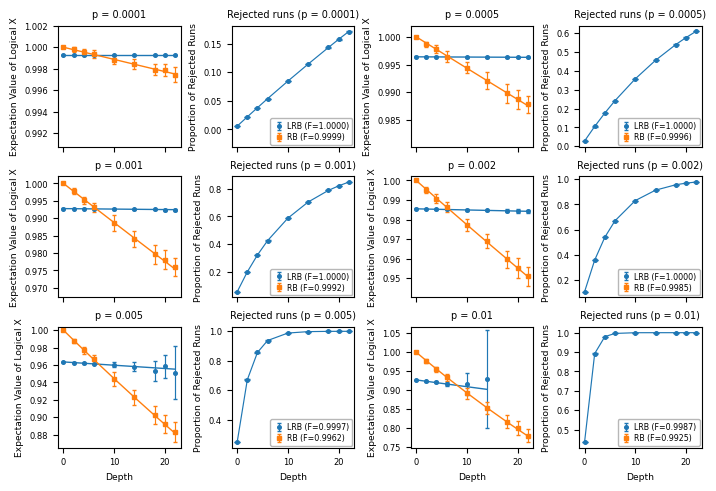

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-22-32-folded_qutrit_conv_sites-conv-sites-si1000-sdim140/results/plots/unif-1-Summary-Graph-Fit.pdf


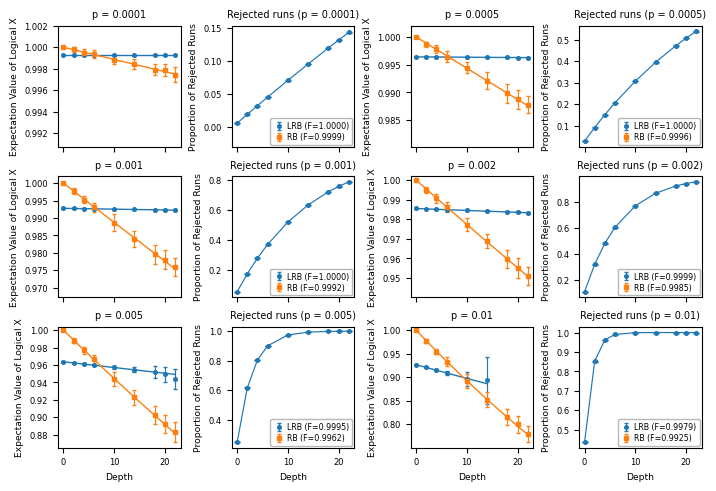

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-22-32-folded_qutrit_conv_sites-conv-sites-si1000-sdim140/results/plots/unif-2-Summary-Graph-Fit.pdf


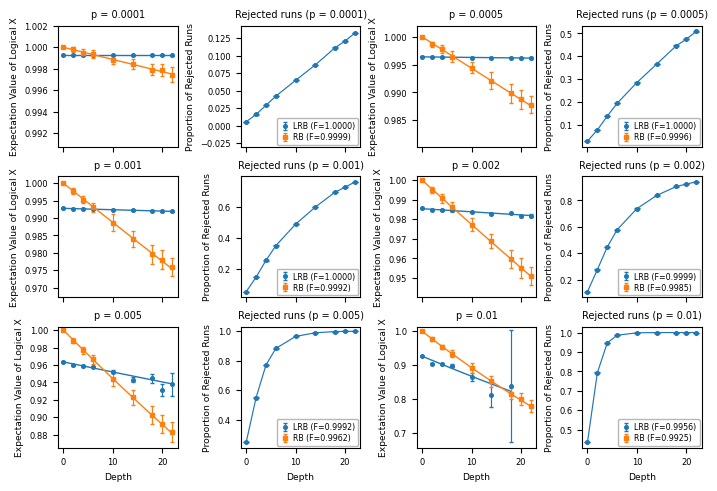

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-22-32-folded_qutrit_conv_sites-conv-sites-si1000-sdim140/results/plots/unif-3-Summary-Graph-Fit.pdf


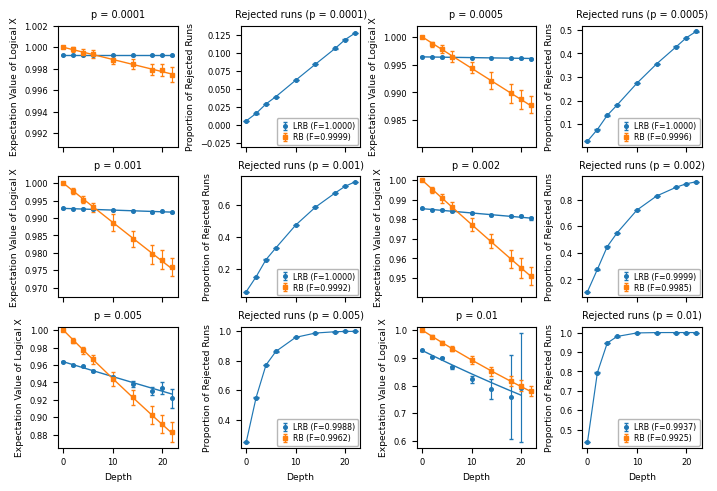

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-22-32-folded_qutrit_conv_sites-conv-sites-si1000-sdim140/results/plots/unif-4-Summary-Graph-Fit.pdf
=== conv_qutrit_sd6


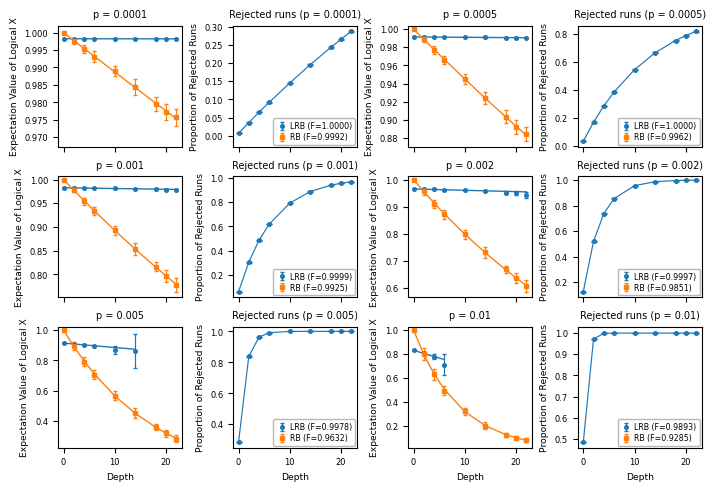

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-24-10-folded_qutrit_conv_sites-conv-sites-sd6-sdim140/results/plots/unif-1-Summary-Graph-Fit.pdf


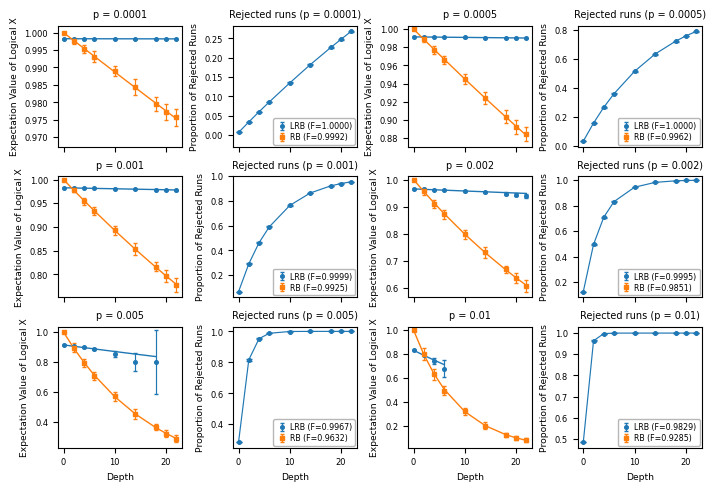

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-24-10-folded_qutrit_conv_sites-conv-sites-sd6-sdim140/results/plots/unif-2-Summary-Graph-Fit.pdf


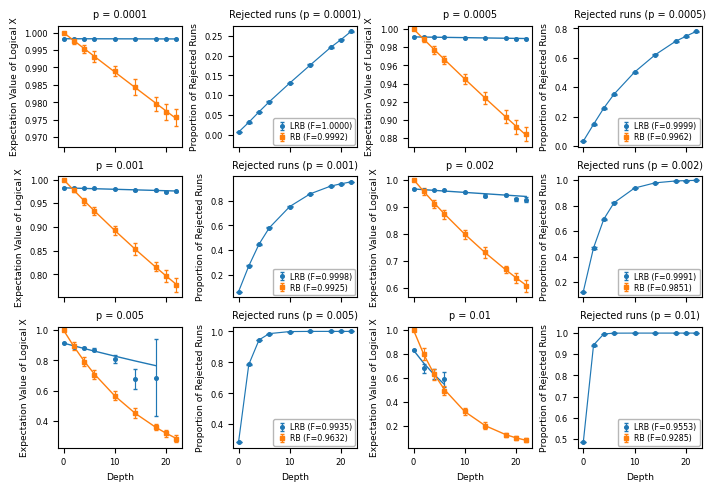

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-24-10-folded_qutrit_conv_sites-conv-sites-sd6-sdim140/results/plots/unif-3-Summary-Graph-Fit.pdf


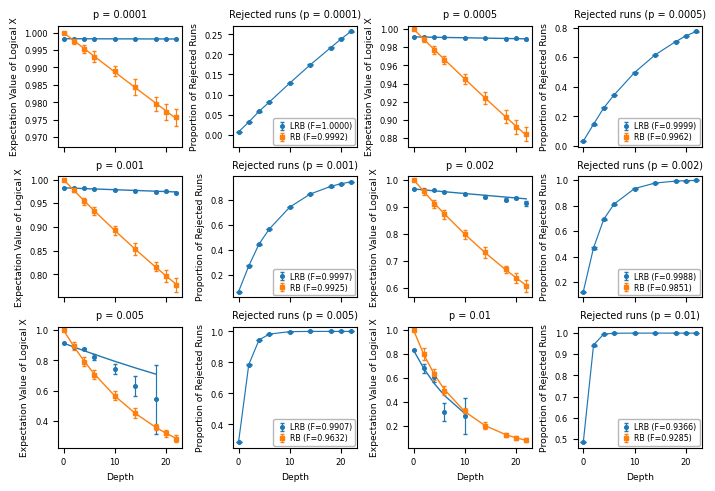

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-24-10-folded_qutrit_conv_sites-conv-sites-sd6-sdim140/results/plots/unif-4-Summary-Graph-Fit.pdf
=== conv_qubit_si1000


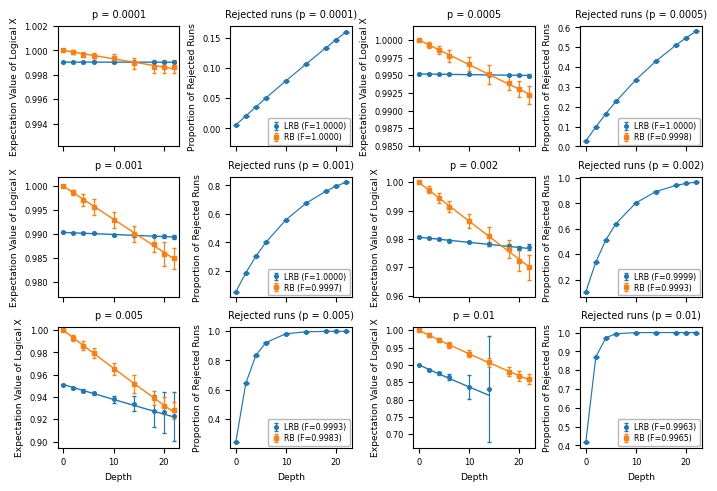

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-26-44-folded_qubit_conv_sites-conv-sites-si1000-sdim140/results/plots/unif-1-Summary-Graph-Fit.pdf


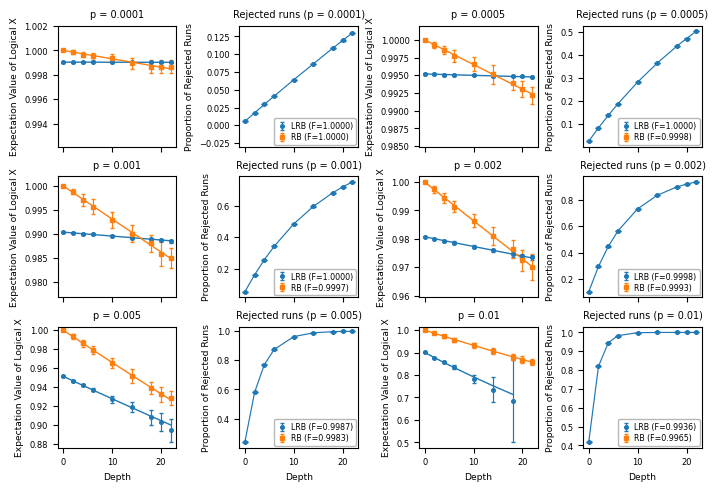

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-26-44-folded_qubit_conv_sites-conv-sites-si1000-sdim140/results/plots/unif-2-Summary-Graph-Fit.pdf


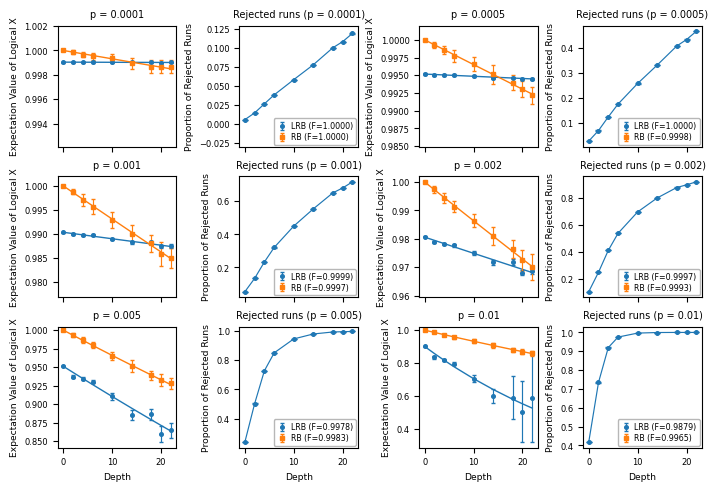

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-26-44-folded_qubit_conv_sites-conv-sites-si1000-sdim140/results/plots/unif-3-Summary-Graph-Fit.pdf


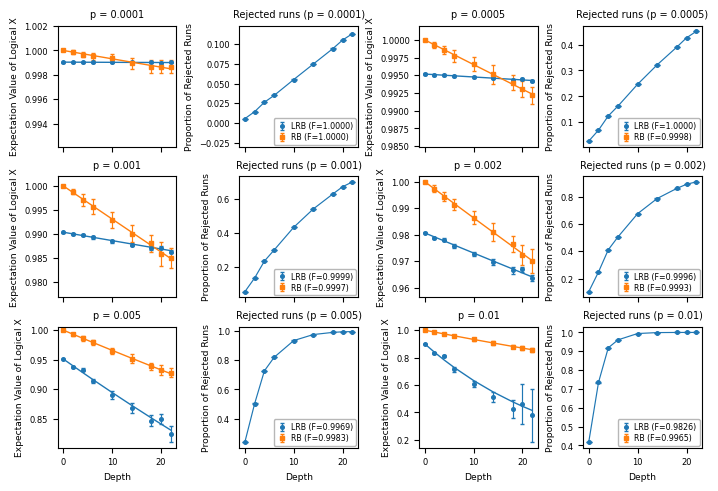

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-26-44-folded_qubit_conv_sites-conv-sites-si1000-sdim140/results/plots/unif-4-Summary-Graph-Fit.pdf
=== conv_qubit_sd6


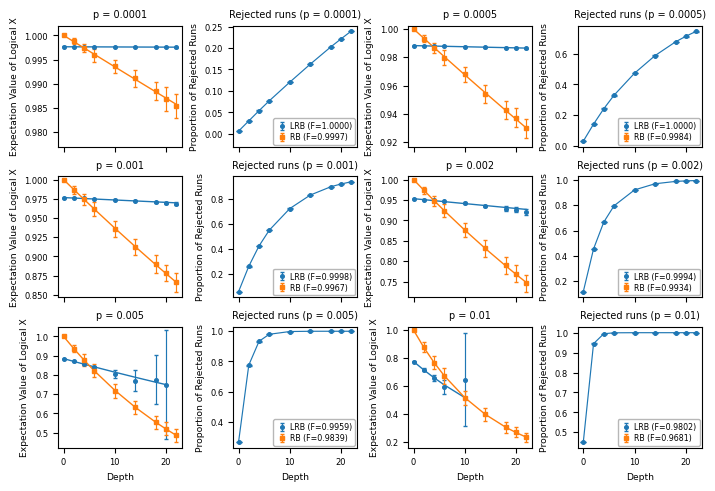

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-28-00-folded_qubit_conv_sites-conv-sites-sd6-sdim140/results/plots/unif-1-Summary-Graph-Fit.pdf


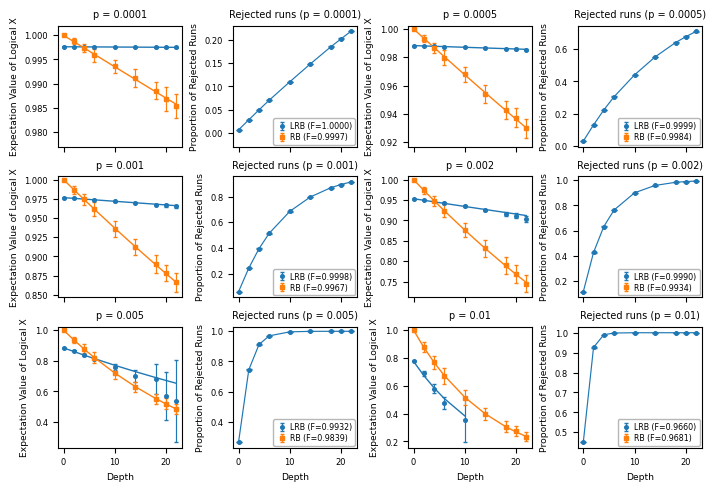

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-28-00-folded_qubit_conv_sites-conv-sites-sd6-sdim140/results/plots/unif-2-Summary-Graph-Fit.pdf


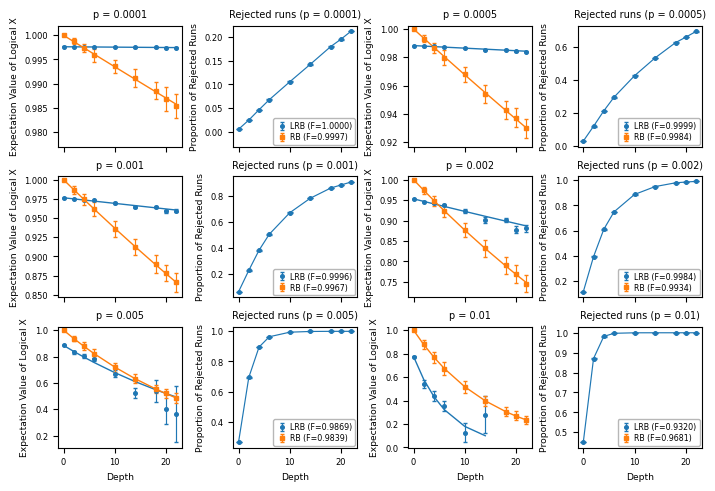

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-28-00-folded_qubit_conv_sites-conv-sites-sd6-sdim140/results/plots/unif-3-Summary-Graph-Fit.pdf


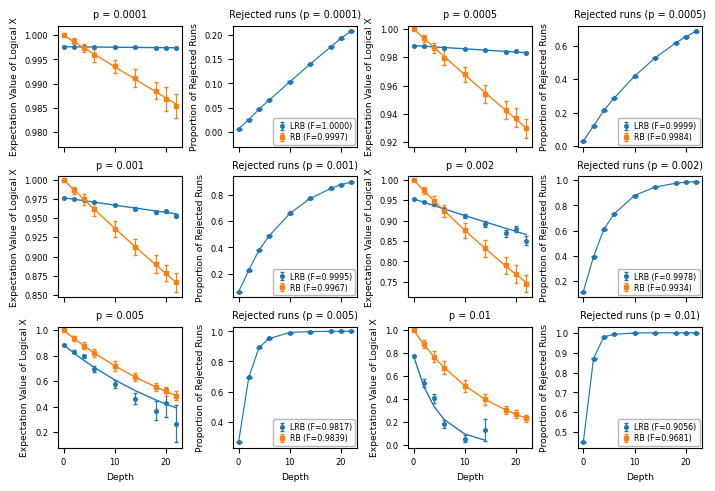

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-28-00-folded_qubit_conv_sites-conv-sites-sd6-sdim140/results/plots/unif-4-Summary-Graph-Fit.pdf


{'conv_qutrit_si1000': ['/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-22-32-folded_qutrit_conv_sites-conv-sites-si1000-sdim140/results/plots/unif-1-Summary-Graph-Fit.pdf',
  '/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-22-32-folded_qutrit_conv_sites-conv-sites-si1000-sdim140/results/plots/unif-2-Summary-Graph-Fit.pdf',
  '/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-22-32-folded_qutrit_conv_sites-conv-sites-si1000-sdim140/results/plots/unif-3-Summary-Graph-Fit.pdf',
  '/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-22-32-folded_qutrit_conv_sites-conv-sites-si1000-sdim140/results/plots/unif-4-Summary-Graph-Fit.pdf'],
 'conv_qutrit_sd6

In [6]:
unif_plot_min, unif_plot_max = 1, 4
unif_outputs = {}
for label, plotter in plotters.items():
    print(f"=== {label}")
    unif_outputs[label] = plotter.plot_all_unif_checks(
        show=True,
        check_min=unif_plot_min,
        check_max=unif_plot_max,
        paper_config=paper_plot_config,
    )
unif_outputs

### 6. LRB-vs-RB tables and threshold summaries

LRB error rates and physical RB error rates are both placed at the same two-qudit gate error $p$. Uncertainties are bootstrap intervals as before.

=== conv_qutrit_si1000


[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-22-32-folded_qutrit_conv_sites-conv-sites-si1000-sdim140/results/plots/unif_lrb_vs_rb_table_all_mixed_fits.csv
[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-22-32-folded_qutrit_conv_sites-conv-sites-si1000-sdim140/results/plots/unif-1-lrb-vs-rb-table-mixed-fits.csv
[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-22-32-folded_qutrit_conv_sites-conv-sites-si1000-sdim140/results/plots/unif-2-lrb-vs-rb-table-mixed-fits.csv
[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-22-32-folded_qutrit_conv_sites-conv-sites-si1000-sdim140/results/plots/unif-3-lrb-vs-rb

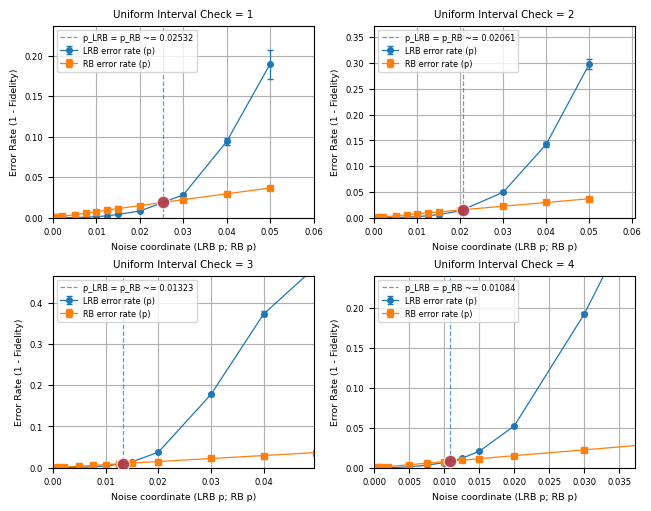

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-22-32-folded_qutrit_conv_sites-conv-sites-si1000-sdim140/results/plots/unif-threshold-error-vs-p-paper-grid.pdf
[THRESHOLD] Uniform Interval Check = 1: p_LRB = p_RB = 0.0253234 +- 0.000746
[THRESHOLD] Uniform Interval Check = 2: p_LRB = p_RB = 0.0206115 +- 0.000131
[THRESHOLD] Uniform Interval Check = 3: p_LRB = p_RB = 0.0132296 +- 6.41e-05
[THRESHOLD] Uniform Interval Check = 4: p_LRB = p_RB = 0.0108369 +- 5.18e-05
[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-22-32-folded_qutrit_conv_sites-conv-sites-si1000-sdim140/results/plots/unif_thresholds_summary_monotone_trim_zoom_pwindow.csv
[conv_qutrit_si1000] error-rate uncertainty table


,check_num,lrb_lambda,rb_p,p_raw,p,lrb_error_rate,lrb_error_rate_ci_low,lrb_error_rate_ci_high,rb_error_rate,rb_error_rate_ci_low,rb_error_rate_ci_high,lrb_unc_minus,lrb_unc_plus,rb_unc_minus,rb_unc_plus
0,1,0.0000,0.0000,0.0000,0.0000,0.000000e+00,0.000000,3.333333e-08,0.000000,0.000000,0.000000,0.000000e+00,3.333333e-08,0.000000,0.000000
1,1,0.0001,0.0001,0.0001,0.0001,0.000000e+00,0.000000,0.000000e+00,0.000076,0.000074,0.000077,0.000000e+00,0.000000e+00,0.000002,0.000002
2,1,0.0002,0.0002,0.0002,0.0002,1.000000e-07,0.000000,4.020000e-07,0.000150,0.000147,0.000152,1.000000e-07,3.020000e-07,0.000003,0.000002
3,1,0.0005,0.0005,0.0005,0.0005,2.647840e-06,0.000002,3.200925e-06,0.000378,0.000373,0.000382,5.775400e-07,5.530850e-07,0.000005,0.000004
4,1,0.0010,0.0010,0.0010,0.0010,9.372510e-06,0.000008,1.023289e-05,0.000755,0.000748,0.000763,9.987600e-07,8.603817e-07,0.000008,0.000007
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
325,22,0.0150,0.0150,0.0150,0.0150,1.202891e-01,0.120096,1.204723e-01,0.011275,0.011192,0.011353,1.926187e-04,1.831893e-04,0.000083,0.000078
326,22,0.0200,0.0200,0.0200,0.0200,1.842021e-01,0.183624,1.847570e-01,0.015045,0.014924,0.015152,5.783040e-04,5.548373e-04,0.000120,0.000107
327,22,0.0300,0.0300,0.0300,0.0300,3.273707e-01,0.325499,3.291834e-01,0.022354,0.022194,0.022507,1.872085e-03,1.812779e-03,0.000160,0.000153
328,22,0.0400,0.0400,0.0400,0.0400,4.120389e-01,0.409051,4.153051e-01,0.029547,0.029322,0.029752,2.987819e-03,3.266197e-03,0.000224,0.000206


[conv_qutrit_si1000] pseudo-threshold uncertainty table


,check_num,threshold_lrb_lambda,threshold_lrb_lambda_std_boot,threshold_lrb_lambda_ci_low,threshold_lrb_lambda_ci_high,threshold_unc_minus,threshold_unc_plus
0,1,0.025323,0.000746,0.024651,0.026087,0.000673,0.000764
1,2,0.020611,0.000131,0.020490,0.020745,0.000122,0.000133
2,3,0.013230,0.000064,0.013163,0.013293,0.000066,0.000064
3,4,0.010837,0.000052,0.010788,0.010892,0.000049,0.000055


=== conv_qutrit_sd6


[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-24-10-folded_qutrit_conv_sites-conv-sites-sd6-sdim140/results/plots/unif_lrb_vs_rb_table_all_mixed_fits.csv
[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-24-10-folded_qutrit_conv_sites-conv-sites-sd6-sdim140/results/plots/unif-1-lrb-vs-rb-table-mixed-fits.csv
[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-24-10-folded_qutrit_conv_sites-conv-sites-sd6-sdim140/results/plots/unif-2-lrb-vs-rb-table-mixed-fits.csv
[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-24-10-folded_qutrit_conv_sites-conv-sites-sd6-sdim140/results/plots/unif-3-lrb-vs-rb-table-mixed

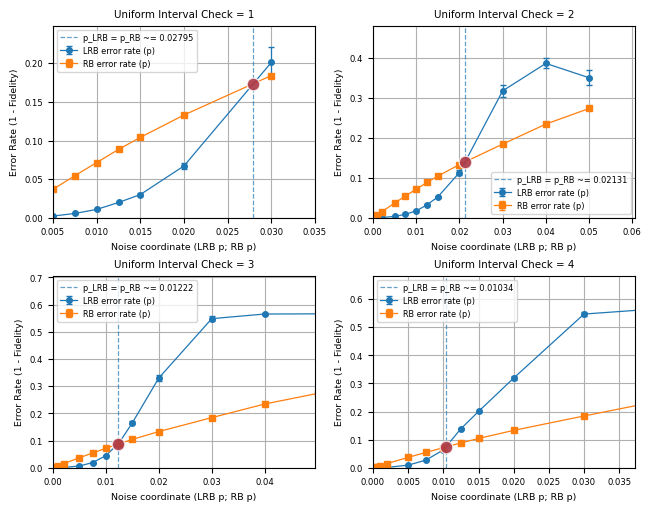

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-24-10-folded_qutrit_conv_sites-conv-sites-sd6-sdim140/results/plots/unif-threshold-error-vs-p-paper-grid.pdf
[THRESHOLD] Uniform Interval Check = 1: p_LRB = p_RB = 0.0279516 +- 0.00143
[THRESHOLD] Uniform Interval Check = 2: p_LRB = p_RB = 0.0213055 +- 0.000353
[THRESHOLD] Uniform Interval Check = 3: p_LRB = p_RB = 0.0122187 +- 0.000214
[THRESHOLD] Uniform Interval Check = 4: p_LRB = p_RB = 0.0103432 +- 5.5e-05
[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-24-10-folded_qutrit_conv_sites-conv-sites-sd6-sdim140/results/plots/unif_thresholds_summary_monotone_trim_zoom_pwindow.csv
[conv_qutrit_sd6] error-rate uncertainty table


,check_num,lrb_lambda,rb_p,p_raw,p,lrb_error_rate,lrb_error_rate_ci_low,lrb_error_rate_ci_high,rb_error_rate,rb_error_rate_ci_low,rb_error_rate_ci_high,lrb_unc_minus,lrb_unc_plus,rb_unc_minus,rb_unc_plus
0,1,0.0000,0.0000,0.0000,0.0000,0.000000,0.000000e+00,3.333333e-08,0.000000,0.000000,0.000000,0.000000e+00,3.333333e-08,0.000000,0.000000
1,1,0.0001,0.0001,0.0001,0.0001,0.000001,7.743333e-07,1.292000e-06,0.000757,0.000751,0.000763,2.406667e-07,2.770000e-07,0.000006,0.000006
2,1,0.0002,0.0002,0.0002,0.0002,0.000004,3.482325e-06,4.352655e-06,0.001507,0.001497,0.001516,4.237750e-07,4.465550e-07,0.000010,0.000009
3,1,0.0005,0.0005,0.0005,0.0005,0.000029,2.746002e-05,2.948637e-05,0.003762,0.003738,0.003785,1.067595e-06,9.587574e-07,0.000023,0.000023
4,1,0.0010,0.0010,0.0010,0.0010,0.000104,1.011617e-04,1.060563e-04,0.007520,0.007479,0.007560,2.393708e-06,2.500960e-06,0.000042,0.000039
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
325,22,0.0150,0.0150,0.0150,0.0150,0.332200,3.293305e-01,3.349981e-01,0.104115,0.103558,0.104643,2.869483e-03,2.798144e-03,0.000557,0.000528
326,22,0.0200,0.0200,0.0200,0.0200,0.418245,4.141262e-01,4.226217e-01,0.133046,0.132047,0.133935,4.118592e-03,4.376896e-03,0.000999,0.000889
327,22,0.0300,0.0300,0.0300,0.0300,0.534179,5.260284e-01,5.419689e-01,0.184191,0.182596,0.185716,8.150272e-03,7.790251e-03,0.001595,0.001524
328,22,0.0400,0.0400,0.0400,0.0400,0.562171,5.569064e-01,5.672639e-01,0.234302,0.231251,0.237110,5.264235e-03,5.093248e-03,0.003051,0.002808


[conv_qutrit_sd6] pseudo-threshold uncertainty table


,check_num,threshold_lrb_lambda,threshold_lrb_lambda_std_boot,threshold_lrb_lambda_ci_low,threshold_lrb_lambda_ci_high,threshold_unc_minus,threshold_unc_plus
0,1,0.027952,0.001434,0.026389,0.030000,0.001562,0.002048
1,2,0.021305,0.000353,0.020962,0.021647,0.000343,0.000342
2,3,0.012219,0.000214,0.012011,0.012493,0.000208,0.000274
3,4,0.010343,0.000055,0.010281,0.010394,0.000063,0.000051


=== conv_qubit_si1000


[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-26-44-folded_qubit_conv_sites-conv-sites-si1000-sdim140/results/plots/unif_lrb_vs_rb_table_all_mixed_fits.csv
[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-26-44-folded_qubit_conv_sites-conv-sites-si1000-sdim140/results/plots/unif-1-lrb-vs-rb-table-mixed-fits.csv
[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-26-44-folded_qubit_conv_sites-conv-sites-si1000-sdim140/results/plots/unif-2-lrb-vs-rb-table-mixed-fits.csv
[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-26-44-folded_qubit_conv_sites-conv-sites-si1000-sdim140/results/plots/unif-3-lrb-vs-rb-tab

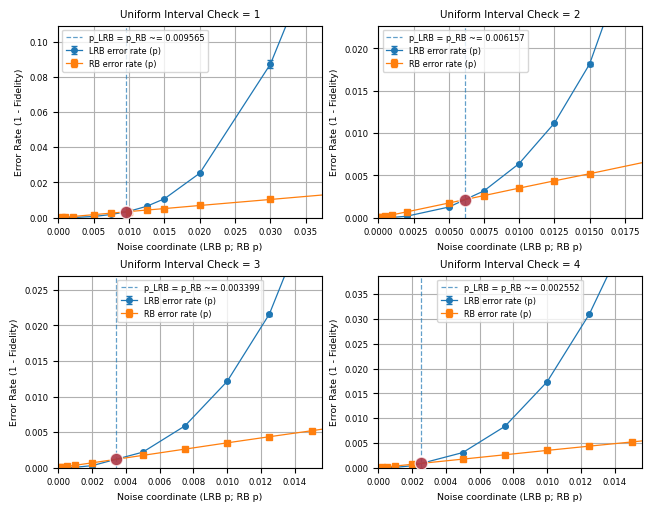

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-26-44-folded_qubit_conv_sites-conv-sites-si1000-sdim140/results/plots/unif-threshold-error-vs-p-paper-grid.pdf
[THRESHOLD] Uniform Interval Check = 1: p_LRB = p_RB = 0.00956539 +- 0.000166
[THRESHOLD] Uniform Interval Check = 2: p_LRB = p_RB = 0.00615683 +- 5.74e-05
[THRESHOLD] Uniform Interval Check = 3: p_LRB = p_RB = 0.0033986 +- 4.1e-05
[THRESHOLD] Uniform Interval Check = 4: p_LRB = p_RB = 0.0025525 +- 1.56e-05
[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-26-44-folded_qubit_conv_sites-conv-sites-si1000-sdim140/results/plots/unif_thresholds_summary_monotone_trim_zoom_pwindow.csv
[conv_qubit_si1000] error-rate uncertainty table


,check_num,lrb_lambda,rb_p,p_raw,p,lrb_error_rate,lrb_error_rate_ci_low,lrb_error_rate_ci_high,rb_error_rate,rb_error_rate_ci_low,rb_error_rate_ci_high,lrb_unc_minus,lrb_unc_plus,rb_unc_minus,rb_unc_plus
0,1,0.0000,0.0000,0.0000,0.0000,0.000000e+00,0.000000e+00,2.500000e-08,0.000000,0.000000,0.000000,0.000000e+00,2.500000e-08,0.000000,0.000000
1,1,0.0001,0.0001,0.0001,0.0001,1.256250e-07,0.000000e+00,3.266250e-07,0.000034,0.000033,0.000035,1.256250e-07,2.010000e-07,0.000001,0.000001
2,1,0.0002,0.0002,0.0002,0.0002,9.690000e-07,7.105000e-07,1.256629e-06,0.000071,0.000070,0.000073,2.585000e-07,2.876295e-07,0.000002,0.000002
3,1,0.0005,0.0005,0.0005,0.0005,4.755585e-06,4.246419e-06,5.221998e-06,0.000175,0.000172,0.000177,5.091662e-07,4.664129e-07,0.000003,0.000003
4,1,0.0010,0.0010,0.0010,0.0010,2.203425e-05,2.110977e-05,2.286983e-05,0.000347,0.000342,0.000351,9.244719e-07,8.355853e-07,0.000005,0.000004
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
325,22,0.0150,0.0150,0.0150,0.0150,1.165340e-01,1.162455e-01,1.168302e-01,0.005195,0.005148,0.005242,2.885280e-04,2.961920e-04,0.000047,0.000047
326,22,0.0200,0.0200,0.0200,0.0200,1.623768e-01,1.616391e-01,1.631494e-01,0.006944,0.006876,0.007006,7.377280e-04,7.726400e-04,0.000068,0.000062
327,22,0.0300,0.0300,0.0300,0.0300,2.581032e-01,2.565660e-01,2.598719e-01,0.010363,0.010270,0.010452,1.537184e-03,1.768672e-03,0.000093,0.000088
328,22,0.0400,0.0400,0.0400,0.0400,3.276832e-01,3.248440e-01,3.304681e-01,0.013806,0.013682,0.013925,2.839152e-03,2.784912e-03,0.000124,0.000119


[conv_qubit_si1000] pseudo-threshold uncertainty table


,check_num,threshold_lrb_lambda,threshold_lrb_lambda_std_boot,threshold_lrb_lambda_ci_low,threshold_lrb_lambda_ci_high,threshold_unc_minus,threshold_unc_plus
0,1,0.009565,0.000166,0.009410,0.009737,0.000155,0.000171
1,2,0.006157,0.000057,0.006103,0.006213,0.000054,0.000056
2,3,0.003399,0.000041,0.003357,0.003438,0.000041,0.000040
3,4,0.002552,0.000016,0.002537,0.002568,0.000015,0.000015


=== conv_qubit_sd6


[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-28-00-folded_qubit_conv_sites-conv-sites-sd6-sdim140/results/plots/unif_lrb_vs_rb_table_all_mixed_fits.csv
[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-28-00-folded_qubit_conv_sites-conv-sites-sd6-sdim140/results/plots/unif-1-lrb-vs-rb-table-mixed-fits.csv
[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-28-00-folded_qubit_conv_sites-conv-sites-sd6-sdim140/results/plots/unif-2-lrb-vs-rb-table-mixed-fits.csv
[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-28-00-folded_qubit_conv_sites-conv-sites-sd6-sdim140/results/plots/unif-3-lrb-vs-rb-table-mixed-fit

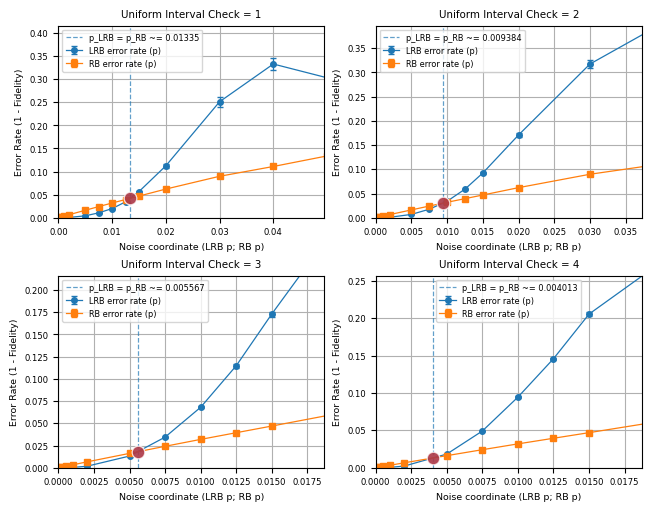

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-28-00-folded_qubit_conv_sites-conv-sites-sd6-sdim140/results/plots/unif-threshold-error-vs-p-paper-grid.pdf
[THRESHOLD] Uniform Interval Check = 1: p_LRB = p_RB = 0.0133501 +- 0.000156
[THRESHOLD] Uniform Interval Check = 2: p_LRB = p_RB = 0.00938446 +- 0.000164
[THRESHOLD] Uniform Interval Check = 3: p_LRB = p_RB = 0.00556662 +- 3.5e-05
[THRESHOLD] Uniform Interval Check = 4: p_LRB = p_RB = 0.00401253 +- 6.89e-05
[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-28-00-folded_qubit_conv_sites-conv-sites-sd6-sdim140/results/plots/unif_thresholds_summary_monotone_trim_zoom_pwindow.csv
[conv_qubit_sd6] error-rate uncertainty table


,check_num,lrb_lambda,rb_p,p_raw,p,lrb_error_rate,lrb_error_rate_ci_low,lrb_error_rate_ci_high,rb_error_rate,rb_error_rate_ci_low,rb_error_rate_ci_high,lrb_unc_minus,lrb_unc_plus,rb_unc_minus,rb_unc_plus
0,1,0.0000,0.0000,0.0000,0.0000,0.000000,0.000000,2.500000e-08,0.000000,0.000000,0.000000,0.000000e+00,2.500000e-08,0.000000,0.000000
1,1,0.0001,0.0001,0.0001,0.0001,0.000002,0.000002,2.152961e-06,0.000327,0.000322,0.000331,2.718475e-07,3.066506e-07,0.000004,0.000004
2,1,0.0002,0.0002,0.0002,0.0002,0.000007,0.000006,7.202947e-06,0.000660,0.000653,0.000666,4.304869e-07,4.636012e-07,0.000007,0.000006
3,1,0.0005,0.0005,0.0005,0.0005,0.000040,0.000039,4.132387e-05,0.001644,0.001629,0.001660,1.120985e-06,1.086437e-06,0.000016,0.000015
4,1,0.0010,0.0010,0.0010,0.0010,0.000160,0.000158,1.628702e-04,0.003253,0.003224,0.003280,2.570536e-06,2.585546e-06,0.000029,0.000027
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
325,22,0.0150,0.0150,0.0150,0.0150,0.254937,0.253111,2.568166e-01,0.046889,0.046521,0.047266,1.825840e-03,1.879776e-03,0.000367,0.000378
326,22,0.0200,0.0200,0.0200,0.0200,0.318253,0.315061,3.209978e-01,0.062080,0.061527,0.062581,3.191920e-03,2.744640e-03,0.000553,0.000501
327,22,0.0300,0.0300,0.0300,0.0300,0.398190,0.393557,4.026891e-01,0.089738,0.088862,0.090520,4.633584e-03,4.498720e-03,0.000876,0.000783
328,22,0.0400,0.0400,0.0400,0.0400,0.438938,0.434984,4.428140e-01,0.110951,0.109645,0.112172,3.954272e-03,3.876000e-03,0.001306,0.001221


[conv_qubit_sd6] pseudo-threshold uncertainty table


,check_num,threshold_lrb_lambda,threshold_lrb_lambda_std_boot,threshold_lrb_lambda_ci_low,threshold_lrb_lambda_ci_high,threshold_unc_minus,threshold_unc_plus
0,1,0.013350,0.000156,0.013208,0.013508,0.000142,0.000158
1,2,0.009384,0.000164,0.009248,0.009561,0.000137,0.000176
2,3,0.005567,0.000035,0.005531,0.005601,0.000036,0.000035
3,4,0.004013,0.000069,0.003942,0.004083,0.000071,0.000070


In [7]:
point_ci_columns = [
    "lrb_error_rate_std_boot",
    "lrb_error_rate_ci_low",
    "lrb_error_rate_ci_high",
    "rb_error_rate_std_boot",
    "rb_error_rate_ci_low",
    "rb_error_rate_ci_high",
]
force_rebuild_uncertainty_table = False


def table_has_point_uncertainty(path: Path) -> bool:
    if not path.exists():
        return False
    columns = pd.read_csv(path, nrows=0).columns
    return all(col in columns for col in point_ci_columns)


table_csvs, summary_csvs, uncertainty_tables, pseudo_threshold_tables = {}, {}, {}, {}
for label, plotter in plotters.items():
    print(f"=== {label}")
    table_csv_path = Path(plotter.out_dir) / "unif_lrb_vs_rb_table_all_mixed_fits.csv"
    if force_rebuild_uncertainty_table or not table_has_point_uncertainty(table_csv_path):
        table_csvs[label] = plotter.build_unif_lrb_vs_rb_table_mixed_fits(
            write_per_check_tables=True,
            check_min=unif_check_min,
            check_max=unif_check_max,
            bootstrap_reps=threshold_config.bootstrap_reps_error,
            bootstrap_ci_level=threshold_config.bootstrap_ci_level,
            bootstrap_use_sem=threshold_config.bootstrap_use_sem,
            bootstrap_seed=threshold_config.bootstrap_seed,
        )
    else:
        table_csvs[label] = str(table_csv_path)
    summary_csvs[label] = plotter.plot_all_unif_threshold_graphs(
        threshold_config=threshold_config,
        table_csv_path=table_csvs[label],
        show=True,
        check_min=unif_check_min,
        check_max=4,
    )
    uncertainty_tables[label] = show_error_rate_uncertainty_table(table_csvs[label], label=label)
    pseudo_threshold_tables[label] = show_pseudo_threshold_uncertainty_table(
        summary_csvs[label],
        label=label,
        check_min=unif_check_min,
        check_max=unif_check_max,
    )

### 7. Pseudo-threshold trend vs interval check

The focused `1..4` pseudo-threshold trend for every run.

[PSEUDO] Uniform Interval Check = 1: p_LRB = p_RB = 0.0253234 +- 0.000746
[PSEUDO] Uniform Interval Check = 2: p_LRB = p_RB = 0.0206115 +- 0.000131
[PSEUDO] Uniform Interval Check = 3: p_LRB = p_RB = 0.0132296 +- 6.41e-05
[PSEUDO] Uniform Interval Check = 4: p_LRB = p_RB = 0.0108369 +- 5.18e-05
[FIT] fit disabled by do_fit=False.


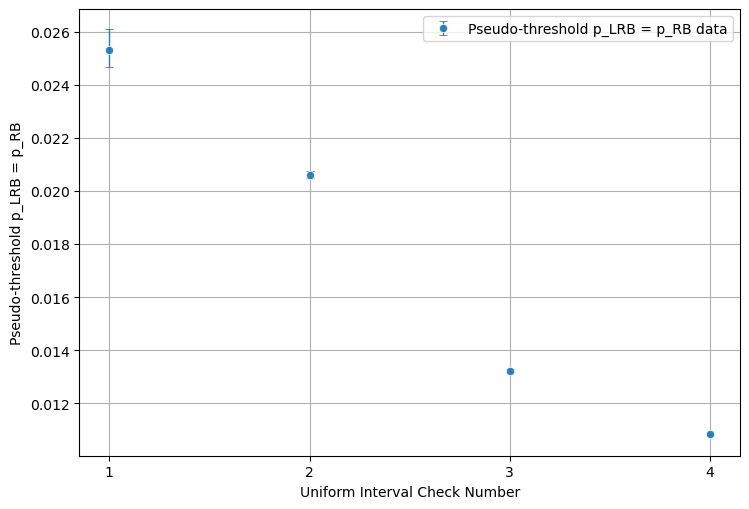

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-22-32-folded_qutrit_conv_sites-conv-sites-si1000-sdim140/results/plots/unif-1-to-4-pseudo-threshold-vs-interval-check-fit.pdf
[PSEUDO] Uniform Interval Check = 1: p_LRB = p_RB = 0.0279516 +- 0.00143
[PSEUDO] Uniform Interval Check = 2: p_LRB = p_RB = 0.0213055 +- 0.000353
[PSEUDO] Uniform Interval Check = 3: p_LRB = p_RB = 0.0122187 +- 0.000214
[PSEUDO] Uniform Interval Check = 4: p_LRB = p_RB = 0.0103432 +- 5.5e-05
[FIT] fit disabled by do_fit=False.


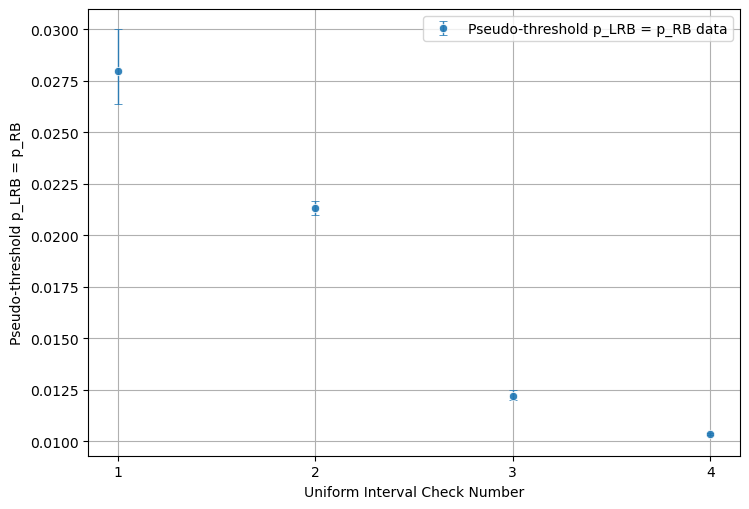

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-24-10-folded_qutrit_conv_sites-conv-sites-sd6-sdim140/results/plots/unif-1-to-4-pseudo-threshold-vs-interval-check-fit.pdf
[PSEUDO] Uniform Interval Check = 1: p_LRB = p_RB = 0.00956539 +- 0.000166
[PSEUDO] Uniform Interval Check = 2: p_LRB = p_RB = 0.00615683 +- 5.74e-05
[PSEUDO] Uniform Interval Check = 3: p_LRB = p_RB = 0.0033986 +- 4.1e-05
[PSEUDO] Uniform Interval Check = 4: p_LRB = p_RB = 0.0025525 +- 1.56e-05
[FIT] fit disabled by do_fit=False.


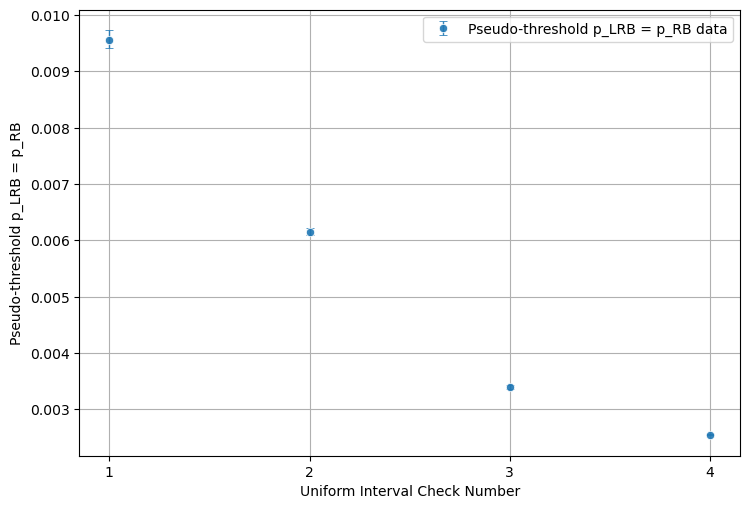

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-26-44-folded_qubit_conv_sites-conv-sites-si1000-sdim140/results/plots/unif-1-to-4-pseudo-threshold-vs-interval-check-fit.pdf
[PSEUDO] Uniform Interval Check = 1: p_LRB = p_RB = 0.0133501 +- 0.000156
[PSEUDO] Uniform Interval Check = 2: p_LRB = p_RB = 0.00938446 +- 0.000164
[PSEUDO] Uniform Interval Check = 3: p_LRB = p_RB = 0.00556662 +- 3.5e-05
[PSEUDO] Uniform Interval Check = 4: p_LRB = p_RB = 0.00401253 +- 6.89e-05
[FIT] fit disabled by do_fit=False.


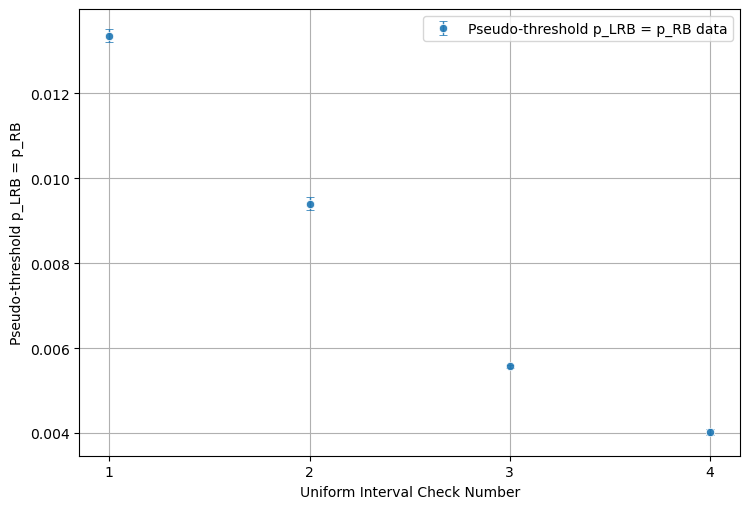

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-28-00-folded_qubit_conv_sites-conv-sites-sd6-sdim140/results/plots/unif-1-to-4-pseudo-threshold-vs-interval-check-fit.pdf


{'conv_qutrit_si1000': '/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-22-32-folded_qutrit_conv_sites-conv-sites-si1000-sdim140/results/plots/unif-1-to-4-pseudo-threshold-vs-interval-check-fit.pdf',
 'conv_qutrit_sd6': '/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-24-10-folded_qutrit_conv_sites-conv-sites-sd6-sdim140/results/plots/unif-1-to-4-pseudo-threshold-vs-interval-check-fit.pdf',
 'conv_qubit_si1000': '/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-26-44-folded_qubit_conv_sites-conv-sites-si1000-sdim140/results/plots/unif-1-to-4-pseudo-threshold-vs-interval-check-fit.pdf',
 'conv_qubit_sd6': '/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-1

In [8]:
pseudo_pdfs = {}
for label, plotter in plotters.items():
    pseudo_pdfs[label] = plotter.plot_unif_pseudo_thresholds_vs_interval_check(
        check_min=unif_check_min,
        check_max=4,
        do_fit=pseudo_do_fit,
        fit_model=pseudo_fit_model,
        fit_degree=pseudo_fit_degree,
        paper_mode=paper_plot_config.enabled,
        show=True,
    )
pseudo_pdfs

### 8. Comparison with the existing layouts

Logical error per Clifford with a check after every Clifford (uniform interval 1) versus the two-qudit gate error $p$, for the one-ancilla runs, the coherent-relay two-ancilla runs (six dedicated ancillas, ancilla-ancilla relay gates) and the conventional-site runs, against physical RB under each noise model. The existing runs' tables are read as saved. Points without a valid fit are omitted.


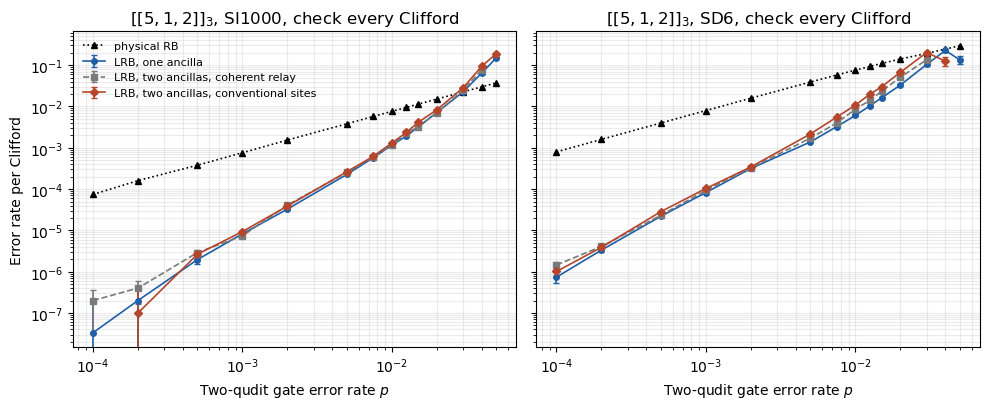

/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/comparisons/sdim140-conv-sites/lrb-vs-rb-unif-1-qutrit-layouts.pdf


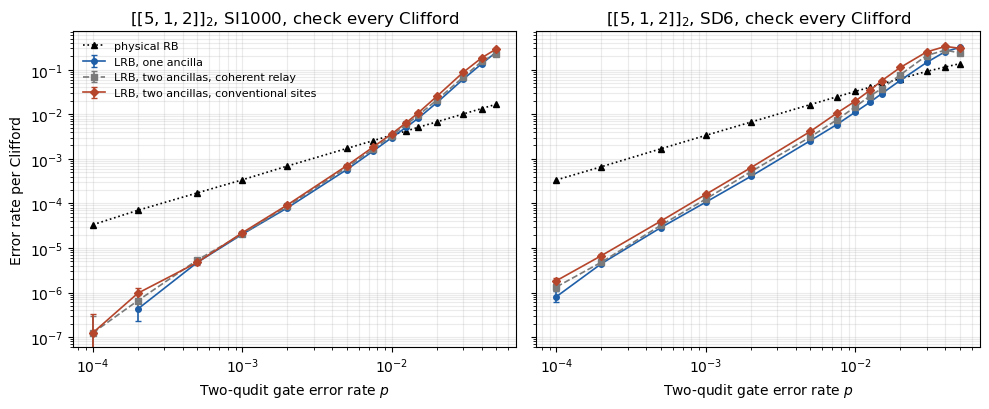

/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/comparisons/sdim140-conv-sites/lrb-vs-rb-unif-1-qubit-layouts.pdf


In [9]:
import matplotlib.pyplot as plt
import numpy as np

comparison_dir = RUNS_ROOT / "comparisons" / "sdim140-conv-sites"
comparison_dir.mkdir(parents=True, exist_ok=True)
comparison_check = 1
TABLE_NAME = "unif_lrb_vs_rb_table_all_mixed_fits.csv"
EXISTING_RUNS = {
    ("qutrit", "si1000", "one ancilla"): "Run-2026-10-28-10-23-30-folded_qutrit-single-ancilla-si1000-sdim140",
    ("qutrit", "sd6", "one ancilla"): "Run-2026-10-28-10-24-46-folded_qutrit-single-ancilla-sd6-sdim140",
    ("qutrit", "si1000", "two ancillas, coherent relay"): "Run-2026-10-28-10-26-06-folded_qutrit_split_unif-split-ancilla-si1000-sdim140",
    ("qutrit", "sd6", "two ancillas, coherent relay"): "Run-2026-10-28-10-27-37-folded_qutrit_split_unif-split-ancilla-sd6-sdim140",
    ("qubit", "si1000", "one ancilla"): "Run-2026-10-31-10-12-55-folded_qubit-single-ancilla-si1000-sdim140",
    ("qubit", "sd6", "one ancilla"): "Run-2026-10-31-10-13-03-folded_qubit-single-ancilla-sd6-sdim140",
    ("qubit", "si1000", "two ancillas, coherent relay"): "Run-2026-10-31-10-12-58-folded_qubit_split_unif-split-ancilla-si1000-sdim140",
    ("qubit", "sd6", "two ancillas, coherent relay"): "Run-2026-10-31-10-13-07-folded_qubit_split_unif-split-ancilla-sd6-sdim140",
}
tables = {key: RUNS_ROOT / run / "results" / "plots" / TABLE_NAME for key, run in EXISTING_RUNS.items()}
for label, table_csv in table_csvs.items():
    _, code, noise = label.split("_")
    tables[(code, noise, "two ancillas, conventional sites")] = Path(table_csv)
styles = {
    "one ancilla": dict(color="#1f5fa8", marker="o", linestyle="-"),
    "two ancillas, coherent relay": dict(color="#7a7a7a", marker="s", linestyle="--"),
    "two ancillas, conventional sites": dict(color="#b5452b", marker="D", linestyle="-"),
}
rows = []
for code, title in (("qutrit", r"$[[5,1,2]]_3$"), ("qubit", r"$[[5,1,2]]_2$")):
    fig, axes = plt.subplots(1, 2, figsize=(10.0, 4.2), sharey=True)
    for ax, noise in zip(axes, ("si1000", "sd6")):
        for layout, style in styles.items():
            frame = pd.read_csv(tables[(code, noise, layout)])
            frame = frame[(frame["check_num"] == comparison_check) & (frame["p"] > 0)].sort_values("p")
            lrb = frame[np.isfinite(frame["lrb_error_rate"]) & (frame["lrb_error_rate"] > 0)]
            yerr = np.vstack([
                lrb["lrb_error_rate"] - lrb["lrb_error_rate_ci_low"],
                lrb["lrb_error_rate_ci_high"] - lrb["lrb_error_rate"],
            ]).clip(min=0)
            ax.errorbar(lrb["p"], lrb["lrb_error_rate"], yerr=yerr, markersize=4, capsize=2,
                        linewidth=1.2, label=f"LRB, {layout}", **style)
            rows.append(frame.assign(code=code, noise=noise, layout=layout))
        frame = pd.read_csv(tables[(code, noise, "one ancilla")])
        frame = frame[(frame["check_num"] == comparison_check) & (frame["p"] > 0)].sort_values("p")
        rb = frame[np.isfinite(frame["rb_error_rate"]) & (frame["rb_error_rate"] > 0)]
        ax.plot(rb["p"], rb["rb_error_rate"], color="black", linestyle=":", marker="^", markersize=4,
                linewidth=1.2, label="physical RB")
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlabel(fit_config.p_axis_label)
        ax.set_title(f"{title}, {noise.upper()}, check every Clifford")
        ax.grid(True, which="both", alpha=0.25)
    axes[0].set_ylabel("Error rate per Clifford")
    axes[0].legend(fontsize=8, frameon=False)
    fig.tight_layout()
    comparison_pdf = comparison_dir / f"lrb-vs-rb-unif-{comparison_check}-{code}-layouts.pdf"
    fig.savefig(comparison_pdf)
    fig.savefig(comparison_pdf.with_suffix(".png"), dpi=160)
    plt.show()
    print(comparison_pdf)
comparison_table = pd.concat(rows, ignore_index=True)[
    ["code", "noise", "layout", "p", "lrb_error_rate", "lrb_error_rate_ci_low", "lrb_error_rate_ci_high",
     "rb_error_rate", "rb_error_rate_ci_low", "rb_error_rate_ci_high"]
]
comparison_table.to_csv(comparison_dir / f"lrb-vs-rb-unif-{comparison_check}-layouts.csv", index=False)


### 9. GIF animations

The const=0 sweep over $p$ and the interval-check sweep at each $p$, per run. This is the slowest step, so it runs last; runs with a complete GIF set are reused.

In [10]:
# GIFs are the slowest step. A run whose GIF set (the const=0 sweep plus one
# interval sweep per p) is already complete is reused; the rest are rebuilt.
gif_outputs = {}
for label, plotter in plotters.items():
    animator = LRBGifAnimator(plotter, render_config=gif_render_config)
    const_gif = animator.out_dir / "const-0-rb-lrb-vs-p.gif"
    interval_gifs = sorted(animator.out_dir.glob("unif-interval-sweep-pidx*.gif"))
    if const_gif.exists() and len(interval_gifs) == len(plotter.probabilities):
        const_gif, interval_gifs = str(const_gif), [str(path) for path in interval_gifs]
    else:
        const_gif = animator.create_const_sweep_gif(const_check=0, strict=True)
        interval_gifs = animator.create_unif_interval_gifs_for_all_probabilities(
            interval_min=unif_check_min,
            interval_max=unif_check_max,
            strict=True,
        )
    gif_outputs[label] = (const_gif, interval_gifs)
    print(f"{label}: {Path(const_gif).name} + {len(interval_gifs)} interval GIFs in {animator.out_dir}")
display(Image(filename=gif_outputs["conv_qutrit_si1000"][0]))

conv_qutrit_si1000: const-0-rb-lrb-vs-p.gif + 15 interval GIFs in /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-22-32-folded_qutrit_conv_sites-conv-sites-si1000-sdim140/results/plots/gifs


conv_qutrit_sd6: const-0-rb-lrb-vs-p.gif + 15 interval GIFs in /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-24-10-folded_qutrit_conv_sites-conv-sites-sd6-sdim140/results/plots/gifs


conv_qubit_si1000: const-0-rb-lrb-vs-p.gif + 15 interval GIFs in /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-26-44-folded_qubit_conv_sites-conv-sites-si1000-sdim140/results/plots/gifs


conv_qubit_sd6: const-0-rb-lrb-vs-p.gif + 15 interval GIFs in /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/conventional-sites/LRB-experiment-data-slurm/Run-2026-11-01-09-28-00-folded_qubit_conv_sites-conv-sites-sd6-sdim140/results/plots/gifs


<GIF animation, not stored; rerun the cell to show it>

## 10. Reading guide

Per-run PDFs, tables and GIFs are under each run's `results/plots/`; the layout comparison is under `LRB-experiment-data-slurm/comparisons/sdim140-conv-sites/`. Pseudo-thresholds with the high-p extensions (qutrit) or near-threshold refinements (qubit) merged in come from `scripts/merge_highp_threshold_extension.py conv-sd6 conv-si1000` and `... qubit-conv-sd6 qubit-conv-si1000`, written to `comparisons/pseudo-thresholds-conv-sites-current.md` and `comparisons/pseudo-thresholds-qubit-conv-sites-current.md`. In every figure the horizontal axis is the two-qudit gate depolarizing probability $p$; SI1000 sets one-qudit gates to $p/10$, measurement flips to $5p$, reset flips and resonator idles to $2p$, and idles to $p/10$, and SD6 sets every operation to $p$.
